`# Explainable Machine-Failure Prediction: AI4I 2020
**Industrial AI · Predictive Maintenance · Explainable AI with quantitative XAI evaluation**

This notebook builds four failure-prediction models (Logistic Regression, Random Forest, XGBoost, MLP) on the
AI4I 2020 Predictive Maintenance dataset and explains them with **SHAP, LIME, Integrated Gradients and
counterfactuals**. It does not stop at the plots. Every explanation is **fed back into the model it explains**,
and the models are re-queried or retrained to score the explanations on seven XAI dimensions:

| Dimension | How the explanation is fed back |
|---|---|
| Faithfulness | remove / keep the top-attributed features, re-query the model; KAR/ROAR retraining |
| Fidelity | use the explanation itself as an additive surrogate and compare it with the model |
| Stability | re-run the explainer on the same input with new seeds / background samples |
| Robustness | re-explain slightly perturbed inputs |
| Consistency | agreement across explainers, across models and with the true failure physics |
| Actionability | act on the top controllable levers and re-query the model **and** a physics simulator |
| Confidence | top-feature consensus across re-runs, attribution dispersion, coupling with model margin |

The loop is then closed: SHAP interaction values propose new features, all models are **retrained**,
**re-explained** and **re-scored**, and baseline and refined models are compared.

**Grad-CAM:** it requires convolutional feature maps over spatial input (images or spectrograms). AI4I has six
scalar sensor readings, so Integrated Gradients fills the gradient-based slot instead.

## 1 · Setup

In [ ]:
!pip install -q shap lime xgboost

In [ ]:
import json, time, warnings, zipfile, io, urllib.request
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.precision", 3)

### Configuration

In [ ]:
"""Global configuration for the explainable predictive-maintenance pipeline."""
from pathlib import Path

ROOT = Path.cwd() / "xai_pm"
DATA_PATH = ROOT / "data" / "ai4i2020.csv"
RESULTS = ROOT / "results"
FIG_DIR = RESULTS / "figures"
TAB_DIR = RESULTS / "tables"

SEED = 42

# Raw sensor / product features (failure-mode flags are dropped: they leak the label).
FEATURES = ["type", "air_temp", "proc_temp", "rpm", "torque", "tool_wear"]
FEATURE_LABELS = {
    "type": "Type (L/M/H)",
    "air_temp": "Air temp [K]",
    "proc_temp": "Process temp [K]",
    "rpm": "Rot. speed [rpm]",
    "torque": "Torque [Nm]",
    "tool_wear": "Tool wear [min]",
}
RENAME = {
    "Type": "type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "proc_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure",
}
TYPE_MAP = {"L": 0, "M": 1, "H": 2}
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Ground-truth relevant features per failure mode (from the AI4I 2020 data-generation rules).
MODE_FEATURES = {
    "TWF": {"tool_wear"},
    "HDF": {"air_temp", "proc_temp", "rpm"},
    "PWF": {"torque", "rpm"},
    "OSF": {"tool_wear", "torque", "type"},
}

# Operator-controllable levers for recourse / counterfactuals.
ACTIONABLE = ["rpm", "torque", "tool_wear"]

# Explanation-evaluation budget.
N_BACKGROUND = 50          # background set used by SHAP / IG
N_EVAL_BACKGROUND = 100    # independent background used for masking in the metrics
N_EVAL_NONFAIL = 100       # non-failure instances in the explanation set (all test failures are used)
N_SUBSET_EVAL = 60         # instances used for the costly stability / robustness tests
N_RERUNS = 5               # explainer re-runs for stability / confidence
N_NOISE = 5                # input perturbations for robustness
NOISE_SCALE = 0.05         # noise std as a fraction of each feature's std
LIME_SAMPLES = 2000
IG_STEPS = 32
IG_BASELINES = 10
FAITH_SUBSETS = 64
TOP_K = 2

MODEL_NAMES = ["LogReg", "RandomForest", "XGBoost", "MLP"]
METHOD_NAMES = ["SHAP", "LIME", "IG"]

# ---- FAST mode: ~3x quicker, smaller explanation budgets (numbers will differ slightly) ----
FAST = False
if FAST:
    N_EVAL_NONFAIL, N_SUBSET_EVAL, N_RERUNS, N_NOISE, LIME_SAMPLES, FAITH_SUBSETS = 40, 30, 3, 3, 1000, 32

for d in (DATA_PATH.parent, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)


## 2 · Data
 official statistics: 10,000 rows, 339 failures, and TWF/HDF/PWF/OSF/RNF = 46/115/95/98/19.

In [ ]:
UCI_ZIP = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
MIRROR = ("https://raw.githubusercontent.com/SamyamoyRakshit/"
          "AI4I-2020-Predictive-Maintenance-Dataset__Linear-Regression/main/ai4i2020.csv")

if not DATA_PATH.exists():
    try:
        raw = urllib.request.urlopen(UCI_ZIP, timeout=60).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            name = next(n for n in z.namelist() if n.endswith(".csv"))
            DATA_PATH.write_bytes(z.read(name))
        print("downloaded from UCI")
    except Exception as e:
        print(f"UCI unavailable ({e.__class__.__name__}); using GitHub mirror")
        DATA_PATH.write_bytes(urllib.request.urlopen(MIRROR, timeout=60).read())

_chk = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
assert _chk.shape == (10000, 14) and _chk["Machine failure"].sum() == 339, "unexpected file contents"
assert _chk[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum().tolist() == [46, 115, 95, 98, 19]
print("dataset verified:", _chk.shape)
_chk.head()

dataset verified: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Loading, splitting, physics simulator and feature engineering
Faliure mode flags kept as ground truth so as to not leak the label .

`physics_modes: re-implements the published AI4I failure-generation rules. They reproduce the HDF, PWF and OSF
labels exactly and are later used to check whether acting on an explanation would fix the *machine*,
not just the model's output.

In [ ]:
#Data loading, splitting, physics-rule simulator and explanation-guided feature engineering.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split



def load_data(path=DATA_PATH):
    df = pd.read_csv(path, encoding="utf-8-sig").rename(columns=RENAME)
    df["type"] = df["type"].map(TYPE_MAP).astype(float)
    X = df[FEATURES].astype(float)
    y = df["failure"].astype(int)
    modes = df[FAILURE_MODES].astype(int)
    return X, y, modes


def split(X, y, modes, seed=SEED):
    #60/20/20 stratified train / validation / test split.
    idx = np.arange(len(X))
    tr, tmp = train_test_split(idx, test_size=0.4, stratify=y, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.5, stratify=y.iloc[tmp], random_state=seed)
    pick = lambda ids: (X.iloc[ids].reset_index(drop=True), y.iloc[ids].reset_index(drop=True),
                        modes.iloc[ids].reset_index(drop=True))
    return pick(tr), pick(va), pick(te)

# Physics simulator: the published AI4I 2020 failure-generation rules (RNF is random and
# TWF is replaced by its deterministic proxy wear >= 200 min). Used to check whether
# explanation-driven actions would make the *real* machine safe, not just fool the model.

OSF_LIMIT = {0: 11000.0, 1: 12000.0, 2: 13000.0}

def physics_modes(X):
    X = np.asarray(X, dtype=float)
    typ, air, proc, rpm, torque, wear = X.T
    power = torque * rpm * 2 * np.pi / 60.0
    osf_lim = np.vectorize(lambda t: OSF_LIMIT[int(round(np.clip(t, 0, 2)))])(typ)
    return {
        "HDF": ((proc - air) < 8.6) & (rpm < 1380),
        "PWF": (power < 3500) | (power > 9000),
        "OSF": wear * torque > osf_lim,
        "TWF": wear >= 200,
    }


def physics_failure(X):
    m = physics_modes(X)
    return m["HDF"] | m["PWF"] | m["OSF"] | m["TWF"]



# Explanation-guided feature engineering

OPS = {
    "mul": lambda a, b: a * b,
    "sub": lambda a, b: a - b,
    "div": lambda a, b: a / (np.abs(b) + 1e-6),
}
OP_SYMBOL = {"mul": "×", "sub": "−", "div": "/"}


class FeatureEngineer:
    #Appends interaction features `a op b` (indices into the raw feature vector)."""

    def __init__(self, specs):
        self.specs = list(specs)  # [(i, j, op), ...]

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        new = [OPS[op](X[:, i], X[:, j]) for i, j, op in self.specs]
        return np.column_stack([X] + new) if new else X

    def names(self, base=FEATURES):
        return list(base) + [f"{base[i]}{OP_SYMBOL[op]}{base[j]}" for i, j, op in self.specs]


In [ ]:
X, y, modes = load_data()
(Xtr_df, ytr, mtr), (Xva_df, yva, mva), (Xte_df, yte, mte) = split(X, y, modes)
Xtr, Xva, Xte = Xtr_df.values, Xva_df.values, Xte_df.values
print(f"{len(X)} rows · failure rate {y.mean():.2%} · train/val/test = {len(Xtr)}/{len(Xva)}/{len(Xte)}")

pm = physics_modes(X.values)
physics_check = pd.DataFrame({k: {"rule_positive": int(pm[k].sum()), "label_positive": int(modes[k].sum()),
                                  "rule_and_label": int((pm[k] & (modes[k] == 1)).sum())}
                              for k in ["HDF", "PWF", "OSF", "TWF"]}).T
physics_check.to_csv(TAB_DIR / "physics_rule_check.csv")
display(physics_check)
display(X.describe().T[["mean", "std", "min", "max"]])

10000 rows · failure rate 3.39% · train/val/test = 6000/2000/2000


,rule_positive,label_positive,rule_and_label
HDF,115,115,115
PWF,95,95,95
OSF,98,98,98
TWF,801,46,45


,mean,std,min,max
type,0.500,0.671,0.0,2.0
air_temp,300.005,2.000,295.3,304.5
proc_temp,310.006,1.484,305.7,313.8
rpm,1538.776,179.284,1168.0,2886.0
torque,39.987,9.969,3.8,76.6
tool_wear,107.951,63.654,0.0,253.0


## 3 · Models

In [ ]:
#Models training, threshold selection and predictive / calibration metrics.
import numpy as np
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier



def make_estimators(pos_weight):
    return {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(
            class_weight="balanced", max_iter=5000, random_state=SEED)),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(
            n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
            colsample_bytree=0.9, scale_pos_weight=pos_weight, eval_metric="logloss",
            n_jobs=4, random_state=SEED),
        "MLP": make_pipeline(StandardScaler(), MLPClassifier(
            hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=2000, early_stopping=True,
            n_iter_no_change=30, random_state=SEED)),
    }


class Model:
    """Wraps an estimator as a function of the RAW 6-feature vector.

    An optional FeatureEngineer is applied inside, so explanations of a refined model
    stay in the same raw feature space as the baseline and are directly comparable.
    """

    def __init__(self, name, estimator, fe=None):
        self.name, self.est, self.fe = name, estimator, fe
        self.threshold = 0.5

    def _t(self, X):
        X = np.asarray(X, dtype=float)
        return self.fe.transform(X) if self.fe is not None else X

    def fit(self, X, y):
        if isinstance(self.est, RandomForestClassifier):
            self.est.n_jobs = -1
        self.est.fit(self._t(X), np.asarray(y))
        if isinstance(self.est, RandomForestClassifier):
            self.est.n_jobs = 1  # explainers call predict thousands of times on small batches
        return self

    def proba(self, X):
        return self.est.predict_proba(self._t(X))[:, 1]

    __call__ = proba

    def predict(self, X):
        return (self.proba(X) >= self.threshold).astype(int)

    def tune_threshold(self, Xv, yv):
        """Pick the validation threshold that maximises F1."""
        p = self.proba(Xv)
        prec, rec, thr = precision_recall_curve(yv, p)
        f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
        self.threshold = float(thr[np.argmax(f1[:-1])])
        return self

    def clone_unfitted(self, fe="same"):
        return Model(self.name, clone(self.est), self.fe if fe == "same" else fe)


def expected_calibration_error(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi) if hi < 1 else (p >= lo) & (p <= hi)
        if m.any():
            ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return ece


def evaluate(model, X, y):
    y = np.asarray(y)
    p = model.proba(X)
    yhat = (p >= model.threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, yhat),
        "balanced_acc": balanced_accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat),
        "f1": f1_score(y, yhat),
        "mcc": matthews_corrcoef(y, yhat),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "ece": expected_calibration_error(y, p),
        "threshold": model.threshold,
    }


def train_models(Xtr, ytr, Xva, yva, fe=None):
    pos_weight = float((ytr == 0).sum() / (ytr == 1).sum())
    models = {}
    for name, est in make_estimators(pos_weight).items():
        m = Model(name, est, fe).fit(Xtr, ytr).tune_threshold(Xva, yva)
        models[name] = m
    return models


In [ ]:
base_models = train_models(Xtr, ytr, Xva, yva)
perf = [{"stage": "baseline", "model": n, **evaluate(m, Xte, yte)} for n, m in base_models.items()]
pd.DataFrame(perf).set_index("model").drop(columns="stage")

,accuracy,balanced_acc,precision,recall,f1,mcc,roc_auc,pr_auc,brier,ece,threshold
model,,,,,,,,,,,
LogReg,0.966,0.727,0.492,0.471,0.481,0.463,0.907,0.416,0.117,0.226,0.882
RandomForest,0.983,0.842,0.770,0.691,0.729,0.721,0.967,0.756,0.015,0.012,0.421
XGBoost,0.984,0.821,0.830,0.647,0.727,0.725,0.977,0.759,0.018,0.020,0.848
MLP,0.981,0.813,0.768,0.632,0.694,0.687,0.976,0.737,0.015,0.004,0.503


## 4 · Explainers
All explainers share one interface: signed attributions towards P(failure), a base value, and the prediction that
the explanation implies.
* **SHAP**: exact interventional Shapley values (all 2⁶ coalitions), model-agnostic.
* **LIME**: tabular LIME with quartile discretisation.
* **IG**: Integrated Gradients via path-integrated central finite differences, averaged over sampled baselines
  (expected gradients). It also works for tree ensembles.

In [ ]:
"""Local attribution methods with a uniform interface.

Every explainer returns signed attributions phi (n, d) towards P(failure), a base value and
the prediction the explanation itself implies (`recon`), so all methods can be scored with
the same XAI metrics. Grad-CAM needs convolutional feature maps and does not apply to tabular
sensor data; Integrated Gradients is its gradient-family counterpart here.
"""
import warnings

import numpy as np
import shap
from lime.lime_tabular import LimeTabularExplainer


warnings.filterwarnings("ignore")


class Explanation:
    def __init__(self, phi, base, recon):
        self.phi = np.asarray(phi, float)
        self.base = np.asarray(base, float)
        self.recon = np.asarray(recon, float)


def shap_explain(f, X, background):
    """Exact interventional Shapley values (2^d coalitions, d = 6)."""
    explainer = shap.explainers.Exact(f, shap.maskers.Independent(background, max_samples=len(background)))
    sv = explainer(np.asarray(X, float), silent=True)
    phi, base = sv.values, np.broadcast_to(sv.base_values, (len(X),))
    return Explanation(phi, base, base + phi.sum(1))


def ig_explain(f, X, background, steps=IG_STEPS, n_baselines=IG_BASELINES, rng=None):
    """Model-agnostic Integrated Gradients averaged over sampled baselines (expected gradients).

    Gradients are central finite differences taken along each path segment, so the method also
    works for tree ensembles whose analytic gradient is zero almost everywhere.
    """
    rng = rng or np.random.default_rng(0)
    X = np.asarray(X, float)
    n, d = X.shape
    bl = background[rng.choice(len(background), size=min(n_baselines, len(background)), replace=False)]
    phi = np.zeros((n, d))
    base = np.zeros(n)
    alphas = (np.arange(steps) + 0.5) / steps
    for b in bl:
        delta = (X - b) / steps                                     # (n, d) step per segment
        mids = b + alphas[None, :, None] * (X - b)[:, None, :]      # (n, steps, d)
        rows = []
        for j in range(d):
            e = np.zeros(d); e[j] = 1
            rows.append(mids + 0.5 * delta[:, None, :] * e)
            rows.append(mids - 0.5 * delta[:, None, :] * e)
        out = f(np.concatenate(rows, axis=1).reshape(-1, d)).reshape(n, 2 * d, steps)
        phi += (out[:, 0::2, :] - out[:, 1::2, :]).sum(-1)
        base += f(np.repeat(b[None], n, 0))
    phi /= len(bl); base /= len(bl)
    return Explanation(phi, base, base + phi.sum(1))


def make_lime(X_train):
    def factory(seed):
        return LimeTabularExplainer(
            np.asarray(X_train, float), feature_names=FEATURES, class_names=["ok", "failure"],
            categorical_features=[0], discretize_continuous=True, mode="classification",
            random_state=seed)
    return factory


def lime_explain(f, X, lime_factory, seed=0, num_samples=LIME_SAMPLES):
    """LIME with quartile discretisation; weights are mapped back to the raw feature index."""
    X = np.asarray(X, float)
    explainer = lime_factory(seed)
    pf = lambda Z: np.column_stack([1 - f(Z), f(Z)])
    phi = np.zeros_like(X); base = np.zeros(len(X)); recon = np.zeros(len(X))
    for i, x in enumerate(X):
        exp = explainer.explain_instance(x, pf, labels=(1,), num_features=X.shape[1],
                                         num_samples=num_samples)
        for j, w in exp.as_map()[1]:
            phi[i, j] = w
        base[i] = exp.intercept[1]
        recon[i] = float(np.ravel(exp.local_pred)[0])
    return Explanation(phi, base, recon)


class ExplainerSuite:
    """Runs SHAP / LIME / IG for one model with a seed-controlled background sample."""

    def __init__(self, X_train, n_background):
        self.X_train = np.asarray(X_train, float)
        self.n_bg = n_background
        self.lime_factory = make_lime(self.X_train)

    def background(self, seed):
        rng = np.random.default_rng(seed)
        return self.X_train[rng.choice(len(self.X_train), self.n_bg, replace=False)]

    def explain(self, method, f, X, seed=0):
        bg = self.background(seed)
        if method == "SHAP":
            return shap_explain(f, X, bg)
        if method == "IG":
            return ig_explain(f, X, bg, rng=np.random.default_rng(seed))
        if method == "LIME":
            return lime_explain(f, X, self.lime_factory, seed=seed)
        raise ValueError(method)


In [ ]:
rng = np.random.default_rng(SEED)
# explanation set: every test failure + random healthy test machines
fail_idx = np.where(yte == 1)[0]
ok_idx = rng.choice(np.where(yte == 0)[0], N_EVAL_NONFAIL, replace=False)
eval_idx = np.concatenate([fail_idx, ok_idx])
Xe, ye, modes_e = Xte[eval_idx], yte.values[eval_idx], mte.iloc[eval_idx].reset_index(drop=True)
half = N_SUBSET_EVAL // 2
sub_idx = np.concatenate([rng.choice(len(fail_idx), half, replace=False),
                          len(fail_idx) + rng.choice(len(ok_idx), half, replace=False)])
suite = ExplainerSuite(Xtr, N_BACKGROUND)
print(f"explanation set: {len(Xe)} instances ({len(fail_idx)} failures); stability/robustness subset: {len(sub_idx)}")

explanation set: 168 instances (68 failures); stability/robustness subset: 60


## 5 · XAI metrics: feeding explanations back into the models
"Masking" a feature means replacing it with values from an independent 100-row background sample and averaging
the model output.

| Metric | Definition | Better |
|---|---|---|
| `faith_corr` | Pearson(Σφ over random subset S, f(x) − f(x with S masked)) | ↑ |
| `comp` / `suff` | probability drop when the top-1..3 features are removed / when only they are kept (AOPC) | ↑ / ↓ |
| `fid_r2` | R² of the explanation used as an additive surrogate on the same coalitions | ↑ |
| `recon_mae`, `decision_agree` | error / class agreement of the explanation-implied prediction | ↓ / ↑ |
| `stab_spearman`, `stab_jaccard` | agreement between 5 re-runs of the explainer on the same input | ↑ |
| `rob_max_sens`, `rob_topk_jaccard` | relative max-sensitivity / top-2 overlap under 5 % input noise | ↓ / ↑ |
| `cons_cross_method`, `cons_cross_model` | rank agreement with the other explainers / the other models | ↑ |
| `cons_ground_truth` | share of the top-2 features that belong to the true failure mechanism | ↑ |
| `act_model@2`, `act_physics@2` | move the top-2 failure-promoting controllable levers to healthy set-points, then re-query the model / the physics simulator | ↑ |
| `cf_alignment` | overlap between the levers a counterfactual had to change and the explainer's top levers | ↑ |
| `conf_top1_consensus`, `conf_rel_dispersion` | top-feature agreement / attribution spread across re-runs | ↑ / ↓ |
| `conf_coupling` | Spearman(model margin, explanation stability), reported but not scored | |

In [ ]:
"""Quantitative XAI metrics.

Explanations are fed back into the model they explain: features are masked / kept / changed
according to the attribution and the model is re-queried. Dimensions:

  faithfulness   faithfulness correlation (Bhatt et al. 2020), comprehensiveness & sufficiency
                 AOPC (DeYoung et al. 2020)
  fidelity       coalition R² of the explanation used as an additive surrogate of the model,
                 reconstruction error and decision agreement of the explanation-implied prediction
  stability      agreement of re-runs of the explainer on the same input (new random seed /
                 background sample)
  robustness     relative max-sensitivity and top-k overlap under small input noise
                 (Yeh et al. 2019; Alvarez-Melis & Jaakkola 2018)
  consistency    cross-method and cross-model rank agreement + agreement with the ground-truth
                 failure physics of AI4I 2020
  actionability  does acting on the top attributed controllable levers fix the prediction, and
                 does it fix the machine according to the physics rules?
  confidence     top-1 consensus over re-runs, attribution dispersion and its coupling with the
                 model's own decision margin
"""
from itertools import combinations

import numpy as np
from scipy.stats import spearmanr


ACT_IDX = [FEATURES.index(a) for a in ACTIONABLE]


#  helpers
def masked_predict(f, x, keep, bg):
    """E_b f(x_keep, b_~keep) for each boolean keep-mask row (marginal / interventional masking)."""
    keep = np.atleast_2d(keep)
    Z = np.where(keep[:, None, :], x[None, None, :], bg[None, :, :])
    return f(Z.reshape(-1, len(x))).reshape(len(keep), len(bg)).mean(1)


def rank_corr(a, b):
    if np.allclose(a, a[0]) or np.allclose(b, b[0]):
        return 1.0 if np.allclose(a, a[0]) and np.allclose(b, b[0]) else 0.0
    return spearmanr(a, b).statistic


def topk(phi, k=TOP_K):
    return set(np.argsort(-np.abs(phi))[:k])


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 1.0


# faithfulness + fidelity
def faithfulness_fidelity(f, X, expls, threshold, eval_bg, rng):
    """Per-instance faithfulness / fidelity for several methods sharing the same coalitions."""
    n, d = X.shape
    p = f(X)
    out = {m: {k: [] for k in ["faith_corr", "fid_r2", "comp", "suff"]} for m in expls}
    for i in range(n):
        x = X[i]
        # random coalitions S to remove (size 1..d-1)
        S = np.zeros((FAITH_SUBSETS, d), bool)
        for s in range(FAITH_SUBSETS):
            S[s, rng.choice(d, rng.integers(1, d), replace=False)] = True
        delta = p[i] - masked_predict(f, x, ~S, eval_bg)
        sign = 1.0 if p[i] >= threshold else -1.0          # explain the predicted class
        g = lambda q: q if sign > 0 else 1 - q
        for m, e in expls.items():
            phi = e.phi[i]
            attr_sum = S.astype(float) @ phi
            if np.std(attr_sum) > 1e-12 and np.std(delta) > 1e-12:
                out[m]["faith_corr"].append(np.corrcoef(attr_sum, delta)[0, 1])
            sst = ((delta - delta.mean()) ** 2).sum()
            if sst > 1e-12:
                r2 = 1 - ((delta - attr_sum) ** 2).sum() / sst
                out[m]["fid_r2"].append(max(r2, -1.0))      # clip pathological scale mismatch
            order = np.argsort(-(sign * phi))
            keep_comp = np.ones((3, d), bool); keep_suff = np.zeros((3, d), bool)
            for k in range(1, 4):
                keep_comp[k - 1, order[:k]] = False
                keep_suff[k - 1, order[:k]] = True
            q = masked_predict(f, x, np.vstack([keep_comp, keep_suff]), eval_bg)
            out[m]["comp"].append(np.mean(g(p[i]) - g(q[:3])))
            out[m]["suff"].append(np.mean(g(p[i]) - g(q[3:])))
    res = {}
    for m, e in expls.items():
        r = {k: float(np.nanmean(v)) if v else np.nan for k, v in out[m].items()}
        r["recon_mae"] = float(np.mean(np.abs(e.recon - p)))
        r["decision_agree"] = float(np.mean((e.recon >= threshold) == (p >= threshold)))
        res[m] = r
    return res


# stability + confidence
def stability_confidence(reruns, margin):
    """reruns: list of Explanation for the same inputs with different seeds."""
    Phi = np.stack([e.phi for e in reruns])            # (R, n, d)
    R, n, d = Phi.shape
    sp, jac, cons, disp = [], [], [], []
    for i in range(n):
        A = np.abs(Phi[:, i, :])
        sp.append(np.mean([rank_corr(A[a], A[b]) for a, b in combinations(range(R), 2)]))
        jac.append(np.mean([jaccard(topk(Phi[a, i]), topk(Phi[b, i])) for a, b in combinations(range(R), 2)]))
        top1 = np.argmax(A, 1)
        cons.append(np.bincount(top1, minlength=d).max() / R)
        disp.append(np.mean(Phi[:, i, :].std(0)) / (np.mean(np.abs(Phi[:, i, :].mean(0))) + 1e-12))
    sp, cons, disp = np.array(sp), np.array(cons), np.array(disp)
    return {
        "stab_spearman": float(sp.mean()),
        "stab_jaccard": float(np.mean(jac)),
        "conf_top1_consensus": float(cons.mean()),
        "conf_rel_dispersion": float(np.median(disp)),
        # do explanations get steadier when the model is more certain?
        "conf_coupling": float(rank_corr(margin, sp)) if len(set(np.round(sp, 6))) > 1 else 0.0,
    }


# robustness
def perturb(X, X_train, rng, n_noise, scale=NOISE_SCALE):
    std = X_train.std(0); lo, hi = X_train.min(0), X_train.max(0)
    noise = rng.normal(size=(n_noise,) + X.shape) * std * scale
    noise[..., FEATURES.index("type")] = 0.0             # product type is categorical: keep it
    return np.clip(X[None] + noise, lo, hi)              # (n_noise, n, d)


def robustness(phi0, phi_noisy, pred0, pred_noisy):
    """phi_noisy: (N, n, d). Relative max-sensitivity + top-k overlap (prediction-preserving)."""
    N, n, d = phi_noisy.shape
    diff = np.linalg.norm(phi_noisy - phi0[None], axis=2)          # (N, n)
    rel = diff.max(0) / (np.linalg.norm(phi0, axis=1) + 1e-12)
    jac = []
    for i in range(n):
        same = [j for j in range(N) if pred_noisy[j, i] == pred0[i]]
        if same:
            jac.append(np.mean([jaccard(topk(phi0[i]), topk(phi_noisy[j, i])) for j in same]))
    return {"rob_max_sens": float(np.median(rel)), "rob_topk_jaccard": float(np.mean(jac))}


# consistency
def cross_agreement(phis):
    """phis: {key: (n, d)}. Mean Spearman of |phi| of each key against all other keys."""
    keys = list(phis)
    res = {}
    for a in keys:
        vals = [np.mean([rank_corr(np.abs(phis[a][i]), np.abs(phis[b][i])) for i in range(len(phis[a]))])
                for b in keys if b != a]
        res[a] = float(np.mean(vals))
    return res


def ground_truth_alignment(phi, modes):
    """Share of the top-k attributed features that belong to the true failure mechanism."""
    scores = []
    for i in range(len(phi)):
        rel = set()
        for mname, feats in MODE_FEATURES.items():
            if modes[mname].iloc[i] == 1:
                rel |= {FEATURES.index(f) for f in feats}
        if rel:
            scores.append(len(topk(phi[i]) & rel) / min(TOP_K, len(rel)))
    return float(np.mean(scores)) if scores else np.nan


# actionability
def healthy_setpoints(X_train, y_train):
    ok = X_train[np.asarray(y_train) == 0]
    sp = {FEATURES.index(a): float(np.median(ok[:, FEATURES.index(a)])) for a in ACTIONABLE}
    sp[FEATURES.index("tool_wear")] = 0.0                  # the lever for wear is a tool change
    return sp


def apply_actions(x, feats, setpoints):
    x = x.copy()
    for j in feats:
        x[j] = setpoints[j]
    return x


def actionability(f, threshold, X, phi, setpoints, k_max=2):
    """Attribution-guided recourse on predicted failures.

    The k most failure-promoting controllable features (phi > 0) are moved to healthy set-points
    and the model is queried again (model recourse); the physics rules check whether the machine
    itself would no longer fail (real recourse).
    """
    pred = f(X) >= threshold
    idx = np.where(pred)[0]
    if len(idx) == 0:
        return {"act_model@1": np.nan, "act_model@2": np.nan, "act_physics@2": np.nan}
    s1, s2, phys = [], [], []
    for i in idx:
        cand = [j for j in sorted(ACT_IDX, key=lambda j: -phi[i, j]) if phi[i, j] > 0][:k_max]
        x1 = apply_actions(X[i], cand[:1], setpoints)
        x2 = apply_actions(X[i], cand[:2], setpoints)
        s1.append(bool(cand) and f(x1[None])[0] < threshold)
        ok2 = bool(cand) and f(x2[None])[0] < threshold
        s2.append(ok2)
        phys.append(ok2 and not physics_failure(x2[None])[0])
    return {"act_model@1": float(np.mean(s1)), "act_model@2": float(np.mean(s2)),
            "act_physics@2": float(np.mean(phys))}


def random_action_baseline(f, threshold, X, setpoints, k=2):
    """Expected recourse success when k controllable levers are picked uniformly at random."""
    idx = np.where(f(X) >= threshold)[0]
    combos = list(combinations(ACT_IDX, k))
    model_ok, phys_ok = [], []
    for i in idx:
        xs = np.array([apply_actions(X[i], c, setpoints) for c in combos])
        m = f(xs) < threshold
        model_ok.append(m.mean())
        phys_ok.append((m & ~physics_failure(xs)).mean())
    return {"act_model@2": float(np.mean(model_ok)), "act_physics@2": float(np.mean(phys_ok))}


### Counterfactual recourse
The search only changes controllable settings: rpm, torque, and tool wear, which can only decrease (a tool change). Product type and temperatures
are immutable. Each counterfactual is then sparsified by pulling every changed feature back towards its original value.

In [ ]:
"""Model-agnostic counterfactual recourse restricted to controllable machine settings.

For each predicted failure, candidates change a subset of {rpm, torque, tool wear} (tool wear can
only go down, i.e. a tool change / earlier replacement; type and ambient conditions are immutable),
keep the cheapest one the model calls healthy, then pull every changed feature back towards its
original value while the prediction stays healthy (sparse, minimal change).
"""
from itertools import combinations

import numpy as np


ACT_IDX = [FEATURES.index(a) for a in ACTIONABLE]
WEAR = FEATURES.index("tool_wear")


class CounterfactualSearch:
    def __init__(self, X_train, y_train, n_samples=400, seed=0):
        X_train = np.asarray(X_train, float)
        self.lo, self.hi = X_train.min(0), X_train.max(0)
        med = np.median(X_train, 0)
        self.mad = np.median(np.abs(X_train - med), 0) + 1e-6
        self.n_samples = n_samples
        self.rng = np.random.default_rng(seed)
        ok = X_train[np.asarray(y_train) == 0]
        self.ok_z = (ok - X_train.mean(0)) / X_train.std(0)
        self.mu, self.sd = X_train.mean(0), X_train.std(0)
        # typical nearest-neighbour distance among healthy points (plausibility scale)
        sub = self.ok_z[self.rng.choice(len(self.ok_z), 500, replace=False)]
        dd = np.linalg.norm(sub[:, None] - self.ok_z[None], axis=2)
        dd[dd == 0] = np.inf
        self.nn_scale = float(np.median(dd.min(1)))

    def cost(self, x, C):
        return (np.abs(C - x) / self.mad).sum(1) + 0.5 * (np.abs(C - x) > 1e-9).sum(1)

    def find(self, f, threshold, x):
        cands = []
        for r in range(1, len(ACT_IDX) + 1):
            for subset in combinations(ACT_IDX, r):
                C = np.repeat(x[None], self.n_samples, 0)
                for j in subset:
                    hi = x[j] if j == WEAR else self.hi[j]
                    C[:, j] = self.rng.uniform(self.lo[j], hi, self.n_samples)
                cands.append(C)
        C = np.vstack(cands)
        valid = f(C) < threshold
        if not valid.any():
            return None
        C = C[valid]
        cf = C[np.argmin(self.cost(x, C))].copy()
        # line-search each changed feature back towards the original value
        for j in np.where(np.abs(cf - x) > 1e-9)[0]:
            ts = np.linspace(0, 1, 21)                     # 0 -> original value, 1 -> current cf
            trial = np.repeat(cf[None], len(ts), 0)
            trial[:, j] = x[j] + ts * (cf[j] - x[j])
            ok = np.where(f(trial) < threshold)[0]
            cf[j] = trial[ok[0], j]
        return cf

    def plausibility(self, cf):
        z = (cf - self.mu) / self.sd
        return float(np.linalg.norm(self.ok_z - z, axis=1).min() / self.nn_scale)


def evaluate_counterfactuals(models, X, searcher):
    """Counterfactual quality per model + transfer to the other models (cross-model validity)."""
    rows, examples = {}, {}
    for name, m in models.items():
        idx = np.where(m(X) >= m.threshold)[0]
        found, sparsity, proximity, plaus, phys, transfer = 0, [], [], [], [], []
        exs = []
        for i in idx:
            cf = searcher.find(m, m.threshold, X[i])
            if cf is None:
                continue
            found += 1
            changed = np.abs(cf - X[i]) > 1e-9
            sparsity.append(changed.sum())
            proximity.append((np.abs(cf - X[i]) / searcher.mad).sum())
            plaus.append(searcher.plausibility(cf))
            phys.append(not physics_failure(cf[None])[0])
            others = [o for o in models.values() if o is not m]
            transfer.append(np.mean([o(cf[None])[0] < o.threshold for o in others]))
            exs.append((i, X[i], cf))
        rows[name] = {
            "cf_validity": found / max(len(idx), 1),
            "cf_sparsity": float(np.mean(sparsity)) if sparsity else np.nan,
            "cf_proximity_mad": float(np.median(proximity)) if proximity else np.nan,
            "cf_plausibility": float(np.median(plaus)) if plaus else np.nan,
            "cf_physics_valid": float(np.mean(phys)) if phys else np.nan,
            "cf_cross_model_valid": float(np.mean(transfer)) if transfer else np.nan,
            "n_predicted_failures": int(len(idx)),
        }
        examples[name] = exs
    return rows, examples


### Explanation → model feedback
* **KAR / ROAR**: retrain every model keeping or removing the top-k features of each explainer's global ranking.
* **Explanation-guided feature engineering**: SHAP interaction values pick the feature pairs the model combines.
  The operator for each pair is chosen by mutual information, with subtraction only allowed between features that
  share a unit. The new features are added inside every model, so inputs and explanations stay in the raw 6-feature space.

In [ ]:
"""Feeding explanations back into the models.

1. KAR / ROAR (Hooker et al. 2019): retrain every model keeping only (or removing) the top-k
   features of each explanation's global ranking. A faithful ranking keeps performance with few
   features (KAR) and destroys it when its top features are removed (ROAR).
2. Explanation-guided feature engineering: SHAP interaction values reveal which feature pairs the
   model combines; the strongest pairs become explicit features, all models are retrained and the
   full XAI evaluation is repeated on the refined models.
"""
from itertools import combinations

import numpy as np
import pandas as pd
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score


# Dimensional analysis: differences are only meaningful between quantities with the same unit.
UNITS = {"type": "-", "air_temp": "K", "proc_temp": "K", "rpm": "1/min", "torque": "Nm", "tool_wear": "min"}


class ColumnSelect:
    def __init__(self, cols):
        self.cols = list(cols)

    def transform(self, X):
        return np.asarray(X, float)[:, self.cols]


def kar_roar(models, rankings, Xtr, ytr, Xte, yte, ks=(1, 2, 3, 4, 5)):
    """rankings: {(model_name, source): [feature indices, most important first]}."""
    cache, rows = {}, []
    d = Xtr.shape[1]
    for (mname, source), order in rankings.items():
        for k in ks:
            for mode, cols in (("KAR", order[:k]), ("ROAR", [c for c in range(d) if c not in order[:k]])):
                key = (mname, frozenset(cols))
                if key not in cache:
                    m = models[mname].clone_unfitted(fe=ColumnSelect(sorted(cols))).fit(Xtr, ytr)
                    cache[key] = average_precision_score(yte, m.proba(Xte))
                rows.append({"model": mname, "source": source, "mode": mode, "k": k, "pr_auc": cache[key]})
    return pd.DataFrame(rows)


def discover_interactions(xgb_model, X_train, y_train, n_pairs=3, n_sample=2000):
    """Rank feature pairs by mean |SHAP interaction| of the XGBoost model; pick the best operator
    for each pair by mutual information with the label."""
    rng = np.random.default_rng(SEED)
    Xs = np.asarray(X_train, float)[rng.choice(len(X_train), n_sample, replace=False)]
    inter = shap.TreeExplainer(xgb_model.est).shap_interaction_values(Xs)
    strength = np.abs(inter).mean(0)
    pairs = sorted(((strength[i, j] + strength[j, i], i, j) for i, j in combinations(range(len(FEATURES)), 2)),
                   reverse=True)
    X = np.asarray(X_train, float)
    specs, table = [], []
    for s, i, j in pairs[:n_pairs]:
        scores = {}
        for op in OPS:
            if op == "sub" and UNITS[FEATURES[i]] != UNITS[FEATURES[j]]:
                continue
            a, b = (i, j) if op != "div" else max([(i, j), (j, i)], key=lambda p: X[:, p[0]].std())
            feat = OPS[op](X[:, a], X[:, b]).reshape(-1, 1)
            scores[(a, b, op)] = mutual_info_classif(feat, y_train, random_state=SEED)[0]
        best = max(scores, key=scores.get)
        specs.append(best)
        table.append({"pair": f"{FEATURES[i]} – {FEATURES[j]}", "interaction_strength": s,
                      "chosen_feature": f"{FEATURES[best[0]]}{OP_SYMBOL[best[2]]}{FEATURES[best[1]]}",
                      "mutual_info": scores[best]})
    return FeatureEngineer(specs), pd.DataFrame(table), strength


### Stage evaluation (runs every metric for every model × explainer)

In [ ]:
"""Runs the complete explanation + XAI-metric evaluation for one set of models (one 'stage')."""
import time

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score


ACT_IDX = [FEATURES.index(a) for a in ACTIONABLE]

# metric -> (dimension, higher_is_better)
METRICS = {
    "faith_corr": ("Faithfulness", True), "comp": ("Faithfulness", True), "suff": ("Faithfulness", False),
    "fid_r2": ("Fidelity", True), "recon_mae": ("Fidelity", False), "decision_agree": ("Fidelity", True),
    "stab_spearman": ("Stability", True), "stab_jaccard": ("Stability", True),
    "rob_max_sens": ("Robustness", False), "rob_topk_jaccard": ("Robustness", True),
    "cons_cross_method": ("Consistency", True), "cons_cross_model": ("Consistency", True),
    "cons_ground_truth": ("Consistency", True),
    "act_model@2": ("Actionability", True), "act_physics@2": ("Actionability", True),
    "cf_alignment": ("Actionability", True),
    "conf_top1_consensus": ("Confidence", True), "conf_rel_dispersion": ("Confidence", False),
}
DIMENSIONS = ["Faithfulness", "Fidelity", "Stability", "Robustness", "Consistency", "Actionability", "Confidence"]


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


def permutation_ranking(model, X, y, repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.proba(X))
    drops = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        for _ in range(repeats):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            drops[j] += base - average_precision_score(y, model.proba(Xp))
    return drops / repeats


def cf_alignment(phi, examples):
    """Do the levers a counterfactual had to change coincide with the top attributed levers?"""
    scores = []
    for i, x, cf in examples:
        changed = {j for j in ACT_IDX if abs(cf[j] - x[j]) > 1e-9}
        if not changed:
            continue
        ranked = sorted(ACT_IDX, key=lambda j: -phi[i, j])[:len(changed)]
        scores.append(jaccard(changed, set(ranked)))
    return float(np.mean(scores)) if scores else np.nan


def evaluate_stage(stage, models, ctx):
    """ctx: dict with Xtr, ytr, Xe, ye, modes_e, sub_idx, suite, eval_bg, setpoints, searcher."""
    Xe, sub = ctx["Xe"], ctx["sub_idx"]
    Xs = Xe[sub]
    rows, phis = [], {}
    rng_noise = np.random.default_rng(SEED + 1)
    Xnoisy = perturb(Xs, ctx["Xtr"], rng_noise, N_NOISE)          # same noise for every model/method
    fail_mask = ctx["ye"] == 1
    for mname, m in models.items():
        t0 = time.time()
        p_e, p_s = m(Xe), m(Xs)
        margin = np.abs(p_s - m.threshold)
        expl = {meth: ctx["suite"].explain(meth, m, Xe, seed=0) for meth in METHOD_NAMES}
        ff = faithfulness_fidelity(m, Xe, expl, m.threshold, ctx["eval_bg"], np.random.default_rng(SEED))
        for meth in METHOD_NAMES:
            phi = expl[meth].phi
            phis[(mname, meth)] = phi
            reruns = [ctx["suite"].explain(meth, m, Xs, seed=s) for s in range(1, N_RERUNS + 1)]
            noisy = ctx["suite"].explain(meth, m, Xnoisy.reshape(-1, Xs.shape[1]), seed=0)
            phi_noisy = noisy.phi.reshape(N_NOISE, len(Xs), -1)
            pred_noisy = (m(Xnoisy.reshape(-1, Xs.shape[1])) >= m.threshold).reshape(N_NOISE, -1)
            row = {"stage": stage, "model": mname, "method": meth, **ff[meth],
                   **stability_confidence(reruns, margin),
                   **robustness(phi[sub], phi_noisy, p_s >= m.threshold, pred_noisy),
                   "cons_ground_truth": ground_truth_alignment(phi[fail_mask], ctx["modes_e"][fail_mask].reset_index(drop=True)),
                   **actionability(m, m.threshold, Xe, phi, ctx["setpoints"])}
            rows.append(row)
        log(f"{stage}: {mname} explained & scored in {time.time() - t0:.0f}s")

    df = pd.DataFrame(rows)
    # consistency across explainers (per model) and across models (per explainer)
    for mname in models:
        ag = cross_agreement({meth: phis[(mname, meth)] for meth in METHOD_NAMES})
        for meth, v in ag.items():
            df.loc[(df.model == mname) & (df.method == meth), "cons_cross_method"] = v
    for meth in METHOD_NAMES:
        ag = cross_agreement({mname: phis[(mname, meth)] for mname in models})
        for mname, v in ag.items():
            df.loc[(df.model == mname) & (df.method == meth), "cons_cross_model"] = v

    # counterfactual recourse (model level) and its alignment with each explainer
    cf_rows, cf_examples = evaluate_counterfactuals(models, Xe, ctx["searcher"])
    for mname in models:
        for meth in METHOD_NAMES:
            df.loc[(df.model == mname) & (df.method == meth), "cf_alignment"] = \
                cf_alignment(phis[(mname, meth)], cf_examples[mname])
    cf_df = pd.DataFrame(cf_rows).T.assign(stage=stage)
    rand = pd.DataFrame({mname: random_action_baseline(m, m.threshold, Xe, ctx["setpoints"])
                         for mname, m in models.items()}).T.assign(stage=stage)
    log(f"{stage}: counterfactuals done")
    return df, phis, cf_df, cf_examples, rand


def dimension_scores(df):
    """Min-max normalise every metric (direction-aware) over all rows, then average per dimension."""
    out = df[["stage", "model", "method"]].copy()
    norm = {}
    for met, (dim, higher) in METRICS.items():
        v = df[met].astype(float)
        lo, hi = v.min(), v.max()
        s = (v - lo) / (hi - lo) if hi > lo else v * 0 + 1.0
        norm[met] = s if higher else 1 - s
    norm = pd.DataFrame(norm)
    for dim in DIMENSIONS:
        cols = [m for m, (d, _) in METRICS.items() if d == dim]
        out[dim] = norm[cols].mean(1)
    out["Overall"] = out[DIMENSIONS].mean(1)
    return out


## 6 · Baseline: explain and score

In [ ]:
ctx = {
    "Xtr": Xtr, "ytr": ytr.values, "Xe": Xe, "ye": ye, "modes_e": modes_e, "sub_idx": sub_idx, "suite": suite,
    "eval_bg": Xtr[np.random.default_rng(SEED + 7).choice(len(Xtr), N_EVAL_BACKGROUND, replace=False)],
    "setpoints": healthy_setpoints(Xtr, ytr),
    "searcher": CounterfactualSearch(Xtr, ytr, seed=SEED),
}
t_start = time.time()
base_df, base_phis, base_cf, base_cf_ex, base_rand = evaluate_stage("baseline", base_models, ctx)
base_df.set_index(["model", "method"]).drop(columns="stage").round(3)

[09:00:16] baseline: LogReg explained & scored in 34s


[09:03:39] baseline: RandomForest explained & scored in 203s


[09:04:33] baseline: XGBoost explained & scored in 54s


[09:05:15] baseline: MLP explained & scored in 42s


[09:05:27] baseline: counterfactuals done


faith_corr  fid_r2   comp   suff  recon_mae  decision_agree  stab_spearman  stab_jaccard  conf_top1_consensus  conf_rel_dispersion  conf_coupling  rob_max_sens  rob_topk_jaccard  cons_ground_truth  \
model        method                                                                                                                                                                                                         
LogReg       SHAP         0.959   0.854  0.428 -0.180      0.000           1.000          0.894         0.848                0.900                0.141         -0.394         0.081             0.956              0.672   
             LIME         0.893   0.227  0.423 -0.174      0.196           0.810          0.934         0.949                0.943                0.078         -0.317         0.189             0.904              0.567   
             IG           0.907   0.395  0.412 -0.171      0.000           1.000          0.845         0.753                0.853                0.219         -0.301         0.082             0.978              0.612   
RandomForest SHAP         0.870   0.501  0.206  0.043      0.000           1.000          0.715         0.692                0.710                0.248         -0.388         0.211             0.936              0.896   
             LIME         0.676  -0.640  0.168  0.073      0.174           0.720          0.861         0.734                0.843                0.170         -0.399         0.343             0.721              0.709   
             IG           0.769  -0.375  0.192  0.051      0.005           0.994          0.570         0.543                0.720                0.679         -0.336         0.222             0.909              0.828   
XGBoost      SHAP         0.862   0.480  0.299  0.028      0.000           1.000          0.669         0.663                0.680                0.232         -0.812         0.229             0.892              0.888   
             LIME         0.614  -0.732  0.226  0.083      0.264           0.732          0.824         0.791                0.870                0.186         -0.388         0.374             0.789              0.791   
             IG           0.711  -0.397  0.279  0.039      0.020           0.988          0.533         0.547                0.713                0.853         -0.778         0.280             0.885              0.873   
MLP          SHAP         0.761   0.232  0.338  0.018      0.000           1.000          0.776         0.760                0.827                0.225         -0.622         0.106             0.964              0.821   
             LIME         0.608  -0.573  0.287  0.033      0.208           0.774          0.862         0.873                0.907                0.154         -0.287         0.285             0.826              0.664   
             IG           0.534   0.011  0.262  0.025      0.001           1.000          0.504         0.522                0.693                1.052         -0.638         0.069             0.949              0.828   

                     act_model@1  act_model@2  act_physics@2  cons_cross_method  cons_cross_model  cf_alignment  
model        method                                                                                              
LogReg       SHAP          1.000        1.000          0.625              0.816             0.500         0.938  
             LIME          1.000        1.000          0.625              0.781             0.606         0.938  
             IG            1.000        1.000          0.625              0.806             0.384         0.906  
RandomForest SHAP          0.979        1.000          0.979              0.628             0.618         0.794  
             LIME          0.851        0.936          0.723              0.546             0.666         0.369  
             IG            1.000        1.000          0.936              0.624             0.594         0.872  
XGBoost      S

## 7 · Feedback A: explanations as feature rankings (KAR / ROAR retraining)

In [ ]:
rankings, glob_rows = {}, []
for mname, m in base_models.items():
    for meth in METHOD_NAMES:
        imp = np.abs(base_phis[(mname, meth)]).mean(0)
        rankings[(mname, meth)] = list(np.argsort(-imp))
        glob_rows.append(pd.Series(imp / imp.sum(), index=FEATURES, name=(mname, meth)))
    perm = permutation_ranking(m, Xva, yva.values)       # validation labels, not test
    rankings[(mname, "Permutation")] = list(np.argsort(-perm))
    glob_rows.append(pd.Series(np.clip(perm, 0, None) / np.clip(perm, 0, None).sum(), index=FEATURES,
                               name=(mname, "Permutation")))
    for r in range(3):
        rankings[(mname, f"Random{r}")] = list(np.random.default_rng(100 + r).permutation(len(FEATURES)))
glob = pd.DataFrame(glob_rows)
glob.index = pd.MultiIndex.from_tuples(glob.index)
glob.to_csv(TAB_DIR / "global_importance_baseline.csv")

kr = kar_roar(base_models, rankings, Xtr, ytr, Xte, yte)
kr.to_csv(TAB_DIR / "kar_roar.csv", index=False)
kr_summary = (kr.assign(source=kr.source.str.replace(r"Random\d", "Random", regex=True))
              .groupby(["model", "source", "mode"]).pr_auc.mean().unstack("mode")
              .rename(columns={"KAR": "KAR_mean_prauc", "ROAR": "ROAR_mean_prauc"}))
kr_summary["KAR_minus_ROAR"] = kr_summary.KAR_mean_prauc - kr_summary.ROAR_mean_prauc
kr_summary.to_csv(TAB_DIR / "kar_roar_summary.csv")
kr_summary.round(3)

mode                      KAR_mean_prauc  ROAR_mean_prauc  KAR_minus_ROAR
model        source                                                      
LogReg       IG                    0.378            0.083           0.295
             LIME                  0.378            0.083           0.295
             Permutation           0.391            0.085           0.307
             Random                0.173            0.299          -0.126
             SHAP                  0.378            0.083           0.295
MLP          IG                    0.564            0.255           0.309
             LIME                  0.514            0.211           0.302
             Permutation           0.487            0.208           0.279
             Random                0.250            0.379          -0.129
             SHAP                  0.545            0.252           0.293
RandomForest IG                    0.502            0.173           0.329
             LIME                  0.491            0.224           0.267
             Permutation           0.485            0.177           0.308
             Random                0.300            0.387          -0.087
             SHAP                  0.502            0.173           0.329
XGBoost      IG                    0.467            0.231           0.236
             LIME                  0.444            0.252           0.192
             Permutation           0.495            0.229           0.266
             Random                0.304            0.381          -0.077
             SHAP                  0.508            0.232           0.276

## 8 · Feedback B: explanation-guided refinement, retrain, re-explain, re-score

In [ ]:
fe, inter_table, strength = discover_interactions(base_models["XGBoost"], Xtr, ytr)
inter_table.to_csv(TAB_DIR / "discovered_interactions.csv", index=False)
display(inter_table)

ref_models = train_models(Xtr, ytr, Xva, yva, fe=fe)
perf += [{"stage": "refined", "model": n, **evaluate(m, Xte, yte)} for n, m in ref_models.items()]
perf = pd.DataFrame(perf)
perf.to_csv(TAB_DIR / "model_performance.csv", index=False)
perf.set_index(["stage", "model"]).round(3)

,pair,interaction_strength,chosen_feature,mutual_info
0,air_temp – rpm,0.879,rpm/air_temp,0.039
1,rpm – torque,0.353,rpm×torque,0.049
2,air_temp – proc_temp,0.295,air_temp/proc_temp,0.012


accuracy  balanced_acc  precision  recall     f1    mcc  roc_auc  pr_auc  brier    ece  threshold
stage    model                                                                                                          
baseline LogReg           0.966         0.727      0.492   0.471  0.481  0.463    0.907   0.416  0.117  0.226      0.882
         RandomForest     0.982         0.842      0.770   0.691  0.729  0.721    0.967   0.756  0.015  0.012      0.421
         XGBoost          0.984         0.821      0.830   0.647  0.727  0.725    0.977   0.759  0.018  0.020      0.848
         MLP              0.981         0.813      0.768   0.632  0.694  0.687    0.976   0.737  0.015  0.004      0.503
refined  LogReg           0.968         0.685      0.542   0.382  0.448  0.439    0.930   0.447  0.094  0.193      0.917
         RandomForest     0.989         0.874      0.911   0.750  0.823  0.821    0.979   0.844  0.011  0.011      0.434
         XGBoost          0.987         0.887      0.828   0.779  0.803  0.797    0.985   0.807  0.014  0.014      0.856
         MLP              0.976         0.839      0.635   0.691  0.662  0.650    0.965   0.670  0.018  0.012      0.264

In [ ]:
ref_df, ref_phis, ref_cf, ref_cf_ex, ref_rand = evaluate_stage("refined", ref_models, ctx)

xai = pd.concat([base_df, ref_df], ignore_index=True)
xai.to_csv(TAB_DIR / "xai_metrics_all.csv", index=False)
scores = dimension_scores(xai)
scores.to_csv(TAB_DIR / "xai_dimension_scores.csv", index=False)
cf = pd.concat([base_cf, ref_cf]); cf.index.name = "model"
cf.to_csv(TAB_DIR / "counterfactual_quality.csv")
rand = pd.concat([base_rand, ref_rand]); rand.index.name = "model"
rand.to_csv(TAB_DIR / "random_action_baseline.csv")
print(f"evaluation finished in {(time.time() - t_start) / 60:.1f} min")

[09:07:27] refined: LogReg explained & scored in 33s


[09:10:45] refined: RandomForest explained & scored in 198s


[09:11:37] refined: XGBoost explained & scored in 52s


[09:12:15] refined: MLP explained & scored in 39s


[09:12:28] refined: counterfactuals done


evaluation finished in 12.8 min


## 9 · Results

In [ ]:
dims = DIMENSIONS + ["Overall"]
display(Markdown("**Explainer comparison: raw metrics, mean over the four models**"))
cols = [c for c in METRICS] + ["conf_coupling"]
display(xai.groupby(["stage", "method"])[cols].mean().T.round(3))
display(Markdown("**Normalised XAI dimension scores** (min-max over all rows, 1 = best observed)"))
display(scores.set_index(["stage", "model", "method"])[dims].round(2))

**Explainer comparison: raw metrics, mean over the four models**

stage               baseline               refined              
method                    IG   LIME   SHAP      IG   LIME   SHAP
faith_corr             0.730  0.697  0.863   0.675  0.656  0.830
comp                   0.286  0.276  0.318   0.250  0.242  0.284
suff                  -0.014  0.004 -0.023   0.012  0.030 -0.005
fid_r2                -0.092 -0.430  0.517  -0.011 -0.494  0.415
recon_mae              0.006  0.210  0.000   0.016  0.198  0.000
decision_agree         0.996  0.759  1.000   0.985  0.769  1.000
stab_spearman          0.613  0.870  0.764   0.653  0.823  0.789
stab_jaccard           0.591  0.837  0.741   0.602  0.819  0.753
rob_max_sens           0.163  0.298  0.157   0.211  0.304  0.110
rob_topk_jaccard       0.930  0.810  0.937   0.885  0.810  0.943
cons_cross_method      0.547  0.499  0.571   0.514  0.452  0.574
cons_cross_model       0.497  0.603  0.573   0.495  0.505  0.611
cons_ground_truth      0.785  0.683  0.819   0.804  0.562  0.826
act_model@2            1.000  0.967  1.000   0.986  0.957  1.000
act_physics@2          0.856  0.719  0.873   0.883  0.741  0.926
cf_alignment           0.862  0.519  0.801   0.869  0.585  0.773
conf_top1_consensus    0.745  0.891  0.779   0.732  0.912  0.859
conf_rel_dispersion    0.701  0.147  0.211   0.884  0.163  0.212
conf_coupling         -0.513 -0.348 -0.554  -0.320 -0.269 -0.282

**Normalised XAI dimension scores** (min-max over all rows, 1 = best observed)

Faithfulness  Fidelity  Stability  Robustness  Consistency  Actionability  Confidence  Overall
stage    model        method                                                                                                
baseline LogReg       SHAP            1.00      1.00       0.84        0.94         0.58           0.67        0.88     0.84
                      LIME            0.94      0.43       1.00        0.67         0.60           0.67        0.98     0.76
                      IG              0.93      0.90       0.67        0.98         0.39           0.65        0.77     0.76
         RandomForest SHAP            0.41      0.93       0.44        0.70         0.79           0.91        0.51     0.67
                      LIME            0.19      0.19       0.66        0.07         0.65           0.28        0.77     0.40
                      IG              0.31      0.73       0.10        0.63         0.71           0.91        0.34     0.53
         XGBoost      SHAP            0.54      0.92       0.36        0.58         0.66           0.96        0.47     0.64
                      LIME            0.21      0.07       0.69        0.15         0.55           0.35        0.81     0.40
                      IG              0.39      0.70       0.06        0.49         0.54           0.93        0.25     0.48
         MLP          SHAP            0.53      0.87       0.60        0.92         0.55           0.74        0.72     0.70
                      LIME            0.33      0.22       0.83        0.36         0.31           0.48        0.89     0.49
                      IG              0.26      0.82       0.00        0.94         0.42           0.85        0.13     0.49
refined  LogReg       SHAP            0.74      0.96       0.79        0.97         0.61           0.73        0.87     0.81
                      LIME            0.63      0.44       0.93        0.60         0.34           0.34        0.99     0.61
                      IG              0.70      0.92       0.57        0.95         0.46           0.78        0.66     0.72
         RandomForest SHAP            0.42      0.89       0.48        0.78         0.85           0.95        0.69     0.72
                      LIME            0.14      0.11       0.56        0.17         0.37           0.50        0.71     0.37
                      IG              0.24      0.74       0.16        0.29         0.68           0.72        0.05     0.41
         XGBoost      SHAP            0.56      0.88       0.57        0.79         0.71           0.88        0.81     0.74
                      LIME            0.18      0.00       0.67        0.12         0.21           0.35        0.91     0.35
                      IG              0.21      0.62       0.11        0.25         0.38           0.88        0.00     0.35
         MLP          SHAP            0.42      0.90       0.56        0.93         0.62           0.86        0.76     0.72
                      LIME            0.31      0.42       0.71        0.33         0.23           0.68        0.96     0.52
                      IG              0.29      0.86       0.23        0.90         0.52           0.90        0.37     0.58

In [ ]:
display(Markdown("**Counterfactual quality per model** (validity = flips the model; physics_valid = fixes the machine)"))
display(cf.round(3))
display(Markdown("**Random-lever recourse baseline** (compare with `act_physics@2` above)"))
display(rand.round(3))

ex_rows = []
for i, x, c in base_cf_ex["XGBoost"][:8]:
    row = {"instance": int(eval_idx[i]),
           "true_mode": ",".join(k for k in FAILURE_MODES if modes_e[k].iloc[i] == 1) or "-"}
    for j, f in enumerate(FEATURES):
        if abs(c[j] - x[j]) > 1e-9:
            row[f] = f"{x[j]:.1f} → {c[j]:.1f}"
    row["P(fail) before → after"] = (f"{base_models['XGBoost'](x[None])[0]:.2f} → "
                                     f"{base_models['XGBoost'](c[None])[0]:.2f}")
    row["physics_ok"] = bool(not physics_failure(c[None])[0])
    ex_rows.append(row)
cf_examples = pd.DataFrame(ex_rows).fillna("")
cf_examples.to_csv(TAB_DIR / "counterfactual_examples_xgboost.csv", index=False)
display(Markdown("**Example counterfactuals (baseline XGBoost)**"))
cf_examples

**Counterfactual quality per model** (validity = flips the model; physics_valid = fixes the machine)

,cf_validity,cf_sparsity,cf_proximity_mad,cf_plausibility,cf_physics_valid,cf_cross_model_valid,n_predicted_failures,stage
model,,,,,,,,
LogReg,1.0,1.000,0.402,1.419,0.281,0.458,32.0,baseline
RandomForest,1.0,1.021,0.312,1.477,0.489,0.589,47.0,baseline
XGBoost,1.0,1.022,0.249,1.466,0.422,0.481,45.0,baseline
MLP,1.0,1.045,0.373,1.426,0.341,0.538,44.0,baseline
LogReg,1.0,1.000,0.617,1.521,0.346,0.346,26.0,refined
RandomForest,1.0,1.039,0.296,1.482,0.725,0.549,51.0,refined
XGBoost,1.0,1.037,0.252,1.472,0.685,0.500,54.0,refined
MLP,1.0,1.000,0.819,1.546,0.383,0.695,47.0,refined


**Random-lever recourse baseline** (compare with `act_physics@2` above)

,act_model@2,act_physics@2,stage
model,,,
LogReg,0.792,0.531,baseline
RandomForest,0.908,0.560,baseline
XGBoost,0.896,0.563,baseline
MLP,0.894,0.583,baseline
LogReg,1.000,0.513,refined
RandomForest,0.719,0.562,refined
XGBoost,0.679,0.568,refined
MLP,0.879,0.553,refined


**Example counterfactuals (baseline XGBoost)**

,instance,true_mode,torque,P(fail) before → after,physics_ok,rpm
0,148,PWF,65.6 → 64.2,0.93 → 0.50,True,
1,213,HDF,,0.99 → 0.66,True,1368.0 → 1380.2
2,438,HDF,,0.97 → 0.79,True,1379.0 → 1380.0
3,441,OSF,68.2 → 60.2,1.00 → 0.64,True,
4,481,OSF,53.8 → 52.8,0.87 → 0.85,False,
5,488,HDF,,0.99 → 0.50,True,1363.0 → 1380.3
6,607,HDF,,0.95 → 0.78,False,1372.0 → 1378.2
7,669,PWF,9.7 → 13.9,0.94 → 0.25,True,


### Figures

In [ ]:
"""Figures (static matplotlib, light theme, validated categorical palette)."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap


SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGE = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
METHOD_COLOR = dict(zip(METHOD_NAMES, SERIES))
STAGE_COLOR = {"baseline": SERIES[0], "refined": SERIES[1]}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})


def save(fig, name):
    if not fig.get_layout_engine():
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=160)
    plt.show()


def performance(perf):
    metrics = [("pr_auc", "PR-AUC"), ("f1", "F1"), ("mcc", "MCC"), ("recall", "Recall")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
    x = np.arange(len(MODEL_NAMES)); w = 0.38
    for ax, (col, label) in zip(axes, metrics):
        for k, stage in enumerate(["baseline", "refined"]):
            v = perf[perf.stage == stage].set_index("model").loc[MODEL_NAMES, col]
            ax.bar(x + (k - 0.5) * (w + 0.01), v, w, color=STAGE_COLOR[stage], label=stage)
        ax.set_xticks(x, MODEL_NAMES, rotation=20); ax.set_title(label); ax.set_ylim(0, 1)
        ax.grid(axis="x", visible=False)
    axes[0].legend(loc="upper left")
    fig.suptitle("Test performance: baseline vs explanation-refined models", fontweight="bold")
    save(fig, "01_performance.png")


def importance_heatmap(glob, name, title):
    """glob: DataFrame rows=(model, method) cols=features, normalised importance."""
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(glob) + 1.4))
    im = ax.imshow(glob.values, cmap=BLUES, aspect="auto", vmin=0, vmax=glob.values.max())
    ax.set_xticks(range(len(FEATURES)), [FEATURE_LABELS[f] for f in FEATURES], rotation=20)
    ax.set_yticks(range(len(glob)), [f"{a} · {b}" for a, b in glob.index])
    for (i, j), v in np.ndenumerate(glob.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if v > 0.55 * glob.values.max() else INK)
    ax.grid(False); ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.025, label="share of mean |attribution|")
    save(fig, name)


def metric_heatmap(df, metrics, name, title):
    vals = df[metrics].astype(float)
    norm = vals.copy()
    for m in metrics:
        lo, hi = vals[m].min(), vals[m].max()
        s = (vals[m] - lo) / (hi - lo) if hi > lo else vals[m] * 0 + 0.5
        norm[m] = s if METRICS[m][1] else 1 - s
    fig, ax = plt.subplots(figsize=(1.0 * len(metrics) + 2.5, 0.4 * len(df) + 1.8))
    ax.imshow(norm.values, cmap=BLUES, aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(len(metrics)), metrics, rotation=40, ha="right")
    ax.set_yticks(range(len(df)), [f"{a} · {b}" for a, b in zip(df.model, df.method)])
    for (i, j), v in np.ndenumerate(vals.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if norm.values[i, j] > 0.6 else INK)
    ax.grid(False); ax.set_title(title)
    save(fig, name)


def dimension_dots(scores):
    """Per-dimension score of each explainer (mean over models), baseline vs refined."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
    dims = DIMENSIONS + ["Overall"]
    y = np.arange(len(dims))[::-1]
    for ax, stage in zip(axes, ["baseline", "refined"]):
        s = scores[scores.stage == stage].groupby("method")[dims].mean()
        for k, meth in enumerate(METHOD_NAMES):
            ax.scatter(s.loc[meth, dims], y + (k - 1) * 0.18, s=60, color=METHOD_COLOR[meth],
                       edgecolor=SURFACE, linewidth=2, label=meth, zorder=3)
        ax.set_yticks(y, dims); ax.set_xlim(-0.05, 1.05); ax.set_title(f"{stage} models")
        ax.set_xlabel("normalised score (1 = best observed)")
        ax.grid(axis="y", visible=False)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93))
    fig.suptitle("XAI quality per dimension (mean over the four models)", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    save(fig, "05_xai_dimensions_by_method.png")


def dimension_delta(scores):
    dims = DIMENSIONS + ["Overall"]
    b = scores[scores.stage == "baseline"].set_index(["model", "method"])[dims]
    r = scores[scores.stage == "refined"].set_index(["model", "method"])[dims]
    delta = (r - b).groupby(level="model").mean().loc[MODEL_NAMES]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    lim = np.abs(delta.values).max()
    ax.imshow(delta.values, cmap=DIVERGE, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(dims)), dims, rotation=20); ax.set_yticks(range(len(delta)), delta.index)
    for (i, j), v in np.ndenumerate(delta.values):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9, color=INK)
    ax.grid(False)
    ax.set_title("Change in XAI dimension score after explanation-guided refinement (blue = better)")
    save(fig, "06_xai_delta_refined_minus_baseline.png")


def kar_roar_plot(kr):
    sources = ["SHAP", "LIME", "IG", "Permutation", "Random"]
    colors = dict(zip(sources, SERIES[:4] + [MUTED]))
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.2), sharey=True)
    for c, mname in enumerate(MODEL_NAMES):
        for r, mode in enumerate(["KAR", "ROAR"]):
            ax = axes[r, c]
            sub = kr[(kr.model == mname) & (kr["mode"] == mode)]
            for src in sources:
                s = sub[sub.source.str.startswith(src)].groupby("k").pr_auc.mean()
                ax.plot(s.index, s.values, marker="o", ms=5, lw=2, color=colors[src], label=src,
                        ls="--" if src == "Random" else "-", mec=SURFACE, mew=1.5)
            ax.set_title(f"{mname} · {mode}"); ax.set_xticks(range(1, 6))
            ax.set_xlabel("k features " + ("kept" if mode == "KAR" else "removed"))
            if c == 0:
                ax.set_ylabel("test PR-AUC after retraining")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=5, bbox_to_anchor=(0.5, 0.95))
    fig.suptitle("Explanations fed back as feature rankings (KAR: higher is better · ROAR: lower is better;"
                 " identical rankings overlap)", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    save(fig, "07_kar_roar.png")


def interaction_heatmap(strength):
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    s = strength.copy(); np.fill_diagonal(s, np.nan)
    im = ax.imshow(s, cmap=BLUES)
    labels = [FEATURE_LABELS[f] for f in FEATURES]
    ax.set_xticks(range(6), labels, rotation=35, ha="right"); ax.set_yticks(range(6), labels)
    for (i, j), v in np.ndenumerate(s):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="#ffffff" if v > 0.6 * np.nanmax(s) else INK)
    ax.grid(False); ax.set_title("Mean |SHAP interaction| (XGBoost)")
    fig.colorbar(im, ax=ax, fraction=0.04)
    save(fig, "08_shap_interactions.png")


def local_example(phis_by_method, x, p, model_name, idx_label):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
    labels = [f"{FEATURE_LABELS[f]} = {v:g}" for f, v in zip(FEATURES, x)]
    for ax, meth in zip(axes, METHOD_NAMES):
        phi = phis_by_method[meth]
        ax.barh(range(len(phi)), phi, color=[SERIES[7] if v > 0 else SERIES[0] for v in phi], height=0.6)
        ax.axvline(0, color=AXIS, lw=1)
        ax.set_yticks(range(len(phi)), labels); ax.invert_yaxis(); ax.set_title(meth)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("contribution to P(failure)  (red → failure)")
    fig.suptitle(f"{model_name} · test instance {idx_label} · P(failure) = {p:.2f}", fontweight="bold")
    save(fig, "04_local_explanations_example.png")


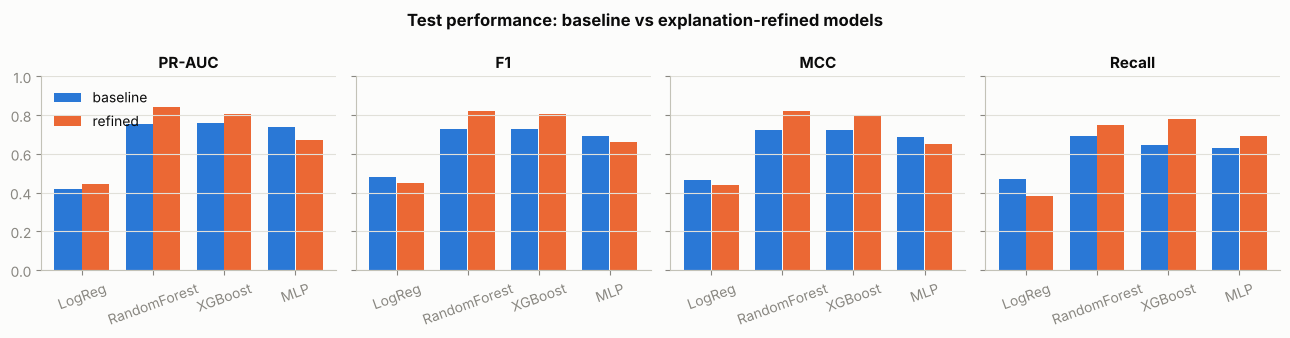

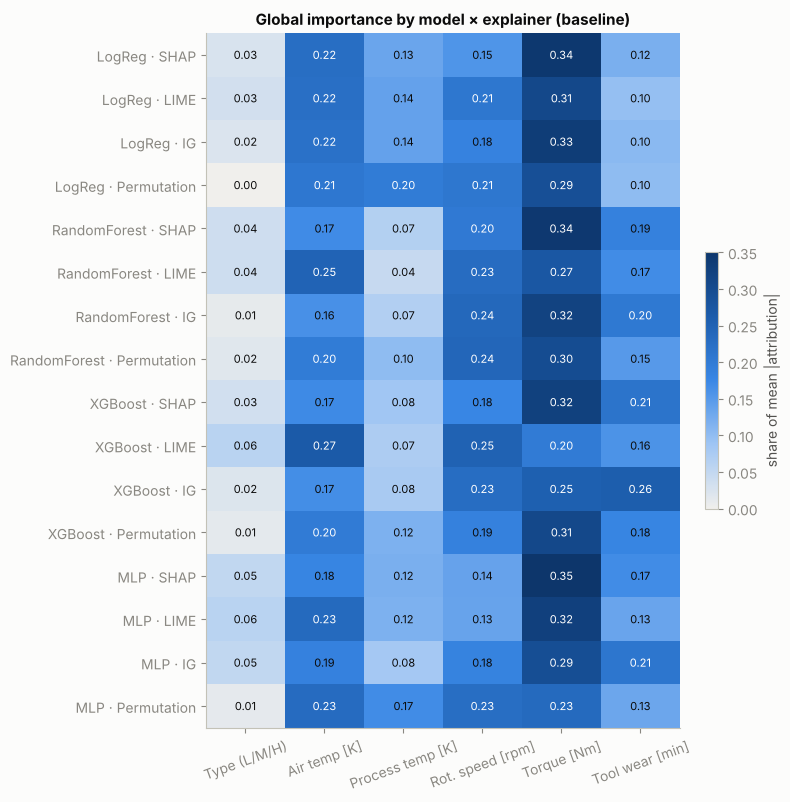

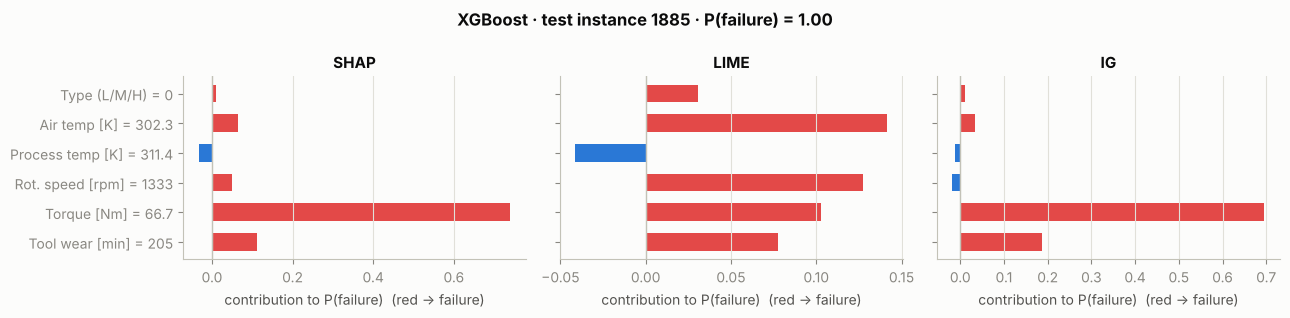

In [ ]:
performance(perf)
importance_heatmap(glob, "03_global_importance_heatmap.png", "Global importance by model × explainer (baseline)")
j = int(np.argmax(base_models["XGBoost"](Xe) * (ye == 1)))
local_example({m: base_phis[("XGBoost", m)][j] for m in METHOD_NAMES}, Xe[j],
              base_models["XGBoost"](Xe[j:j + 1])[0], "XGBoost", int(eval_idx[j]))

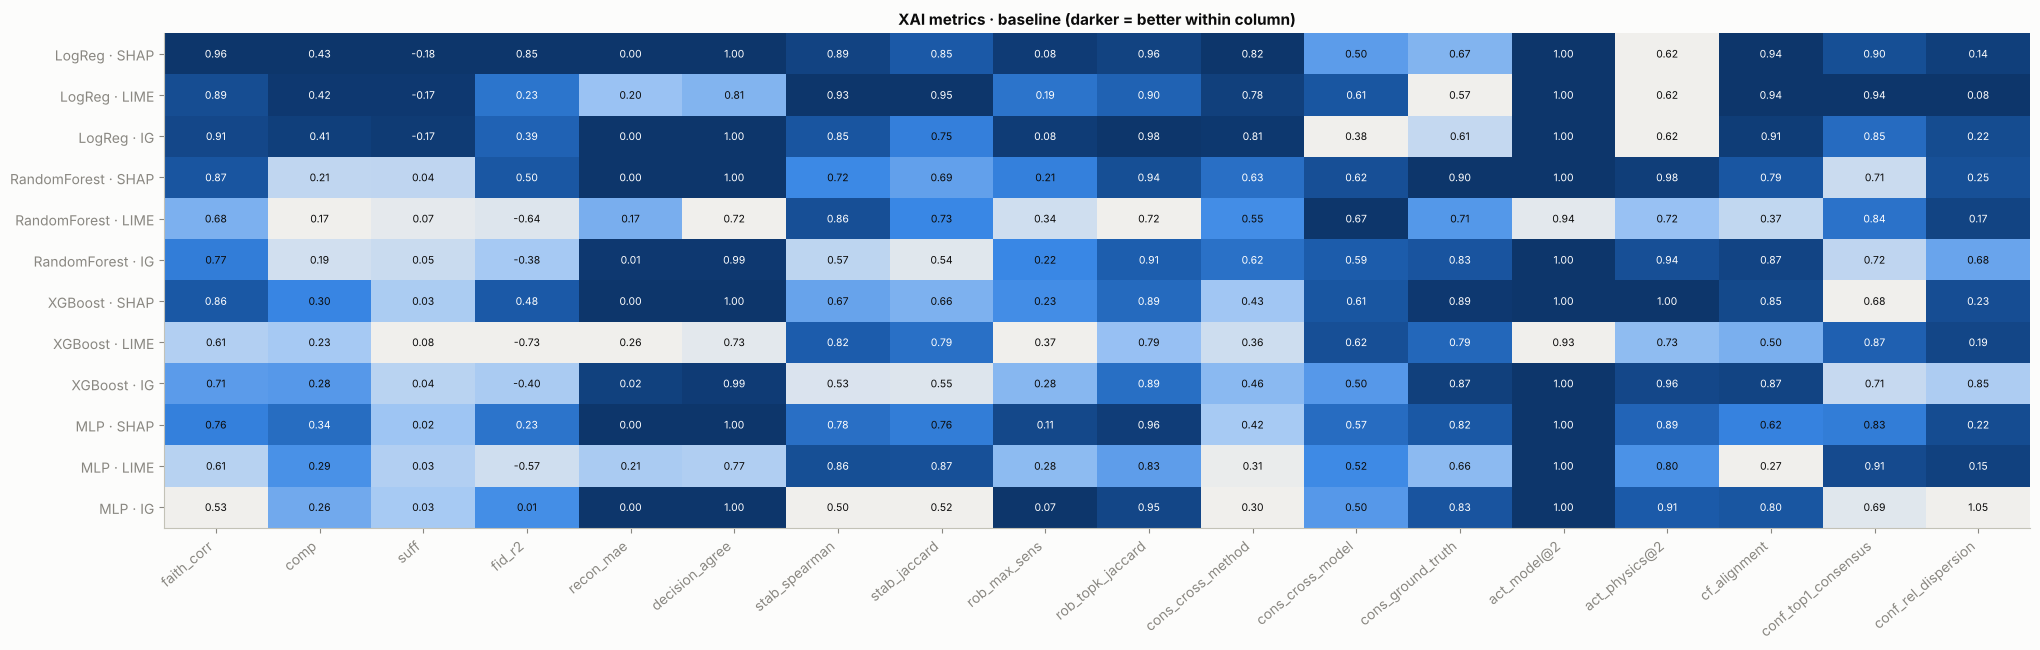

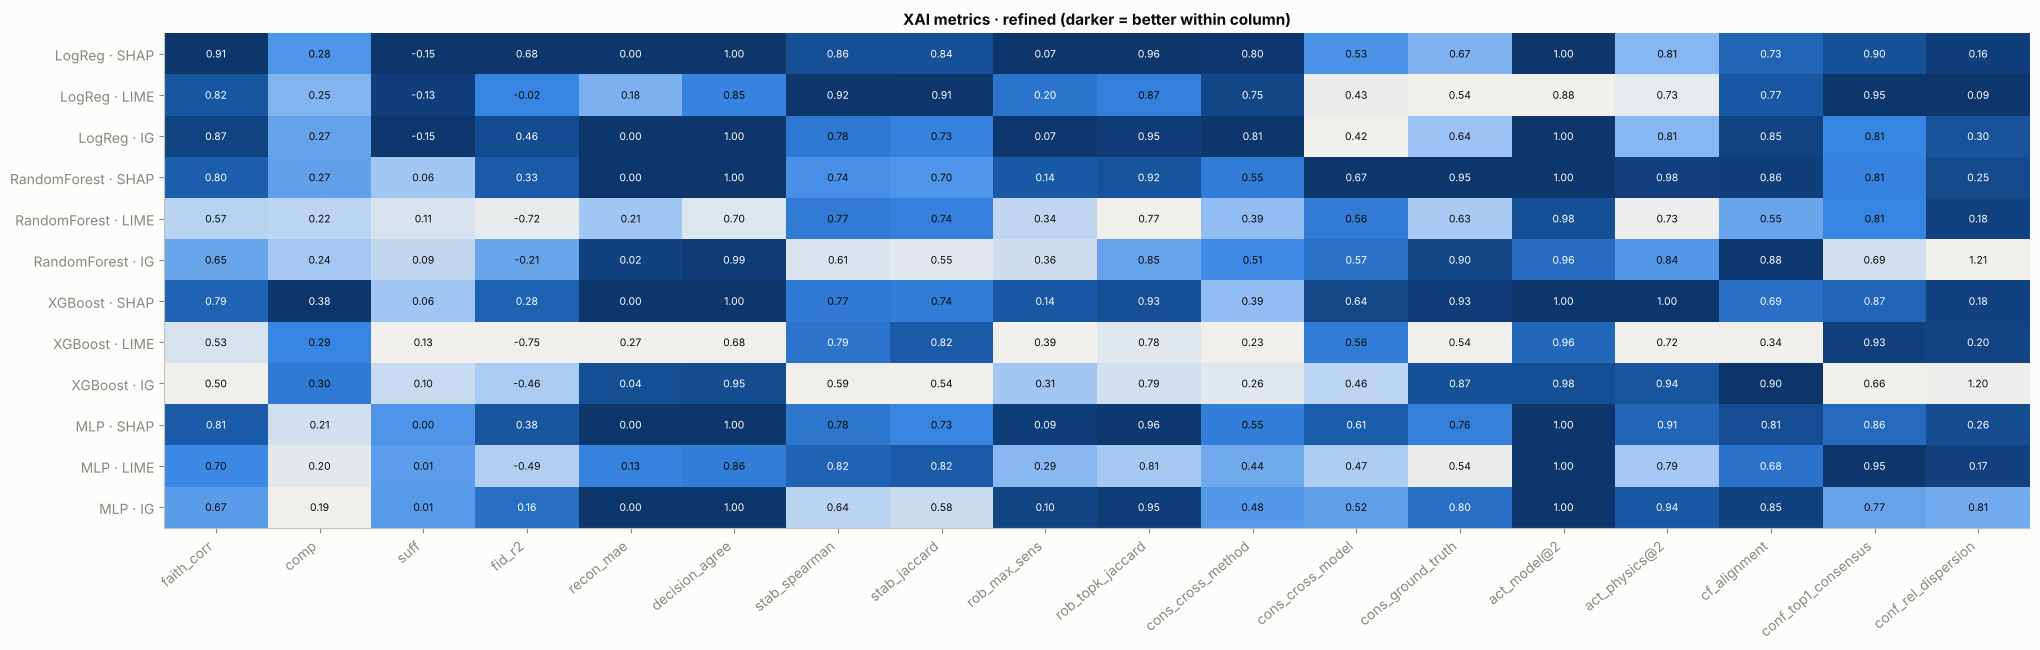

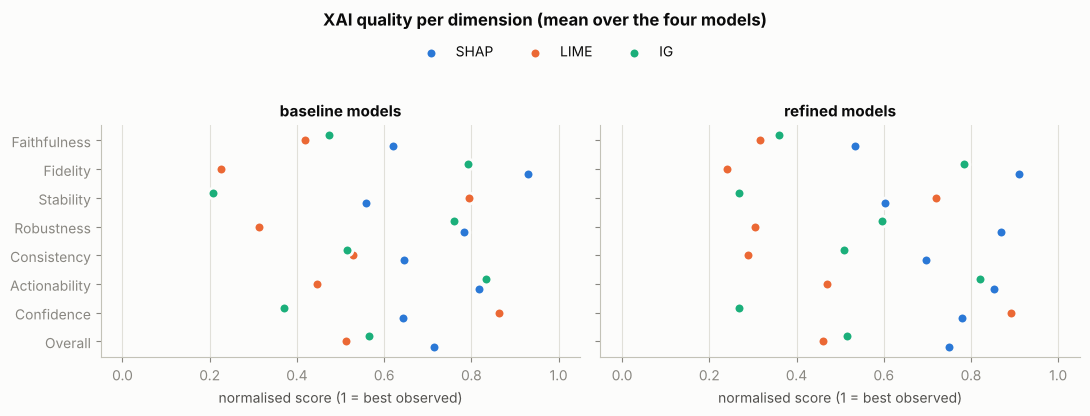

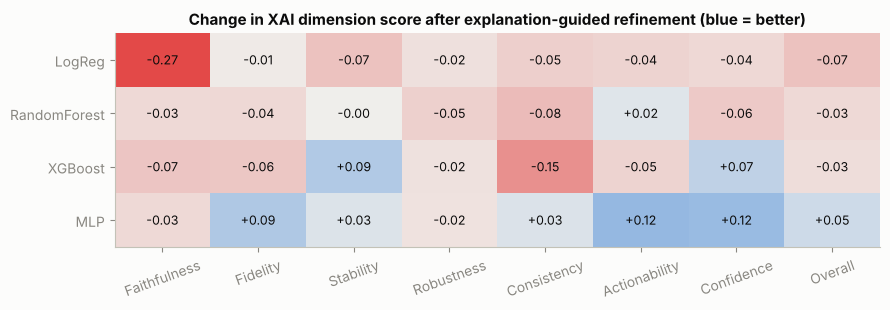

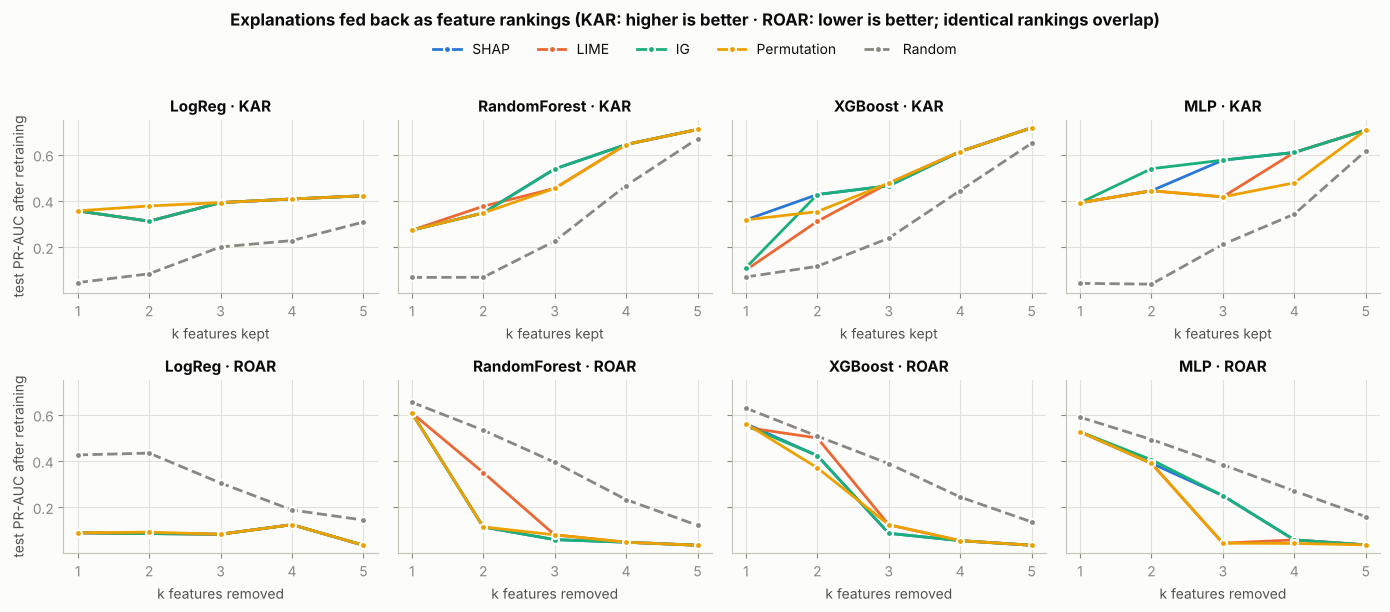

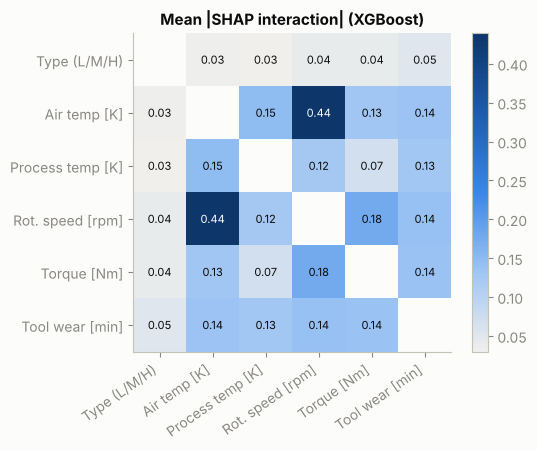

In [ ]:
core = list(METRICS)
metric_heatmap(base_df, core, "09_xai_metrics_baseline.png", "XAI metrics · baseline (darker = better within column)")
metric_heatmap(ref_df, core, "10_xai_metrics_refined.png", "XAI metrics · refined (darker = better within column)")
dimension_dots(scores)
dimension_delta(scores)
kar_roar_plot(kr)
interaction_heatmap(strength)

## 10 · Interpretation (reference run)
These findings come from the reference run: seed 42, full budget. Different library versions or \FAST = True move
individual numbers slightly, but the pattern should hold.

1. **No explainer wins on every dimension.** SHAP has the best overall score: faithfulness ≈ 0.86, fidelity R² ≈ 0.52,
   ground-truth alignment ≈ 0.82, and physics-valid recourse ≈ 0.87 (≈ 0.93 after refinement). LIME is the most stable and
   most confident explainer (re-run Spearman ≈ 0.87) but the **least faithful and robust**: fidelity R² < 0, and its surrogate
   disagrees with the model on about 24 % of decisions. LIME is consistently wrong in a reproducible way, so stability alone cannot certify an explanation.
2. **IG is nearly complete but depends on its baseline.** Its attributions add up to the prediction (MAE ≈ 0.006), but it is the least stable
   explainer because the result depends on which reference machine is used as the baseline.
3. **A faithful explanation of a wrong model is still misleading.** Logistic regression has the most faithful explanations but the lowest
   ground-truth alignment (≈ 0.62, against 0.81–0.85 for the tree models). A linear model cannot represent the PWF power band
   or the HDF AND-rule.
4. **Model-valid recourse is not machine-valid recourse.** 100 % of counterfactuals flip the model, but only about 28–49 % would
   actually stop the failure under the physics rules. Many are minimal nudges that stop just short of the real boundary.
5. **Closing the loop pays off for the tree models.** The SHAP-interaction features (rpm×torque` ≈ power,
   air_temp/proc_temp ≈ heat dissipation) raise RF PR-AUC from ≈ 0.76 to ≈ 0.84 and XGBoost from ≈ 0.76 to ≈ 0.81. Physics-valid
   counterfactuals rise from ≈ 0.49 to ≈ 0.73 (RF) and ≈ 0.42 to ≈ 0.69 (XGB), and SHAP robustness and consensus improve.
6. **The cost is raw-feature faithfulness.** Faithfulness and fidelity R² drop slightly because the refined models rely more on
   interactions between the raw inputs. The MLP and LR did not gain accuracy. Better accuracy does not automatically mean better explanations,
   so both have to be measured.
7. **Model confidence does not imply explanation confidence.** Explanation stability is *negatively* correlated with the model's
   decision margin: on saturated predictions the attributions are tiny and their ranking is noisy.

**Caveats:** the removal-based metrics favour SHAP, because they work the same way it does (an independent background sample reduces but does not remove this bias).
Dimension scores are relative to this study. There is a single split and seed. The TWF rule is a proxy (wear ≥ 200 min).